In [236]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [237]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_excel("data/tourists.xlsx")
df.head()

,"Number and nights spent of tourists by countries of origin, 2011-2024, by municipality, by month",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 368,Unnamed: 369,Unnamed: 370,Unnamed: 371,Unnamed: 372,Unnamed: 373,Unnamed: 374,Unnamed: 375,Unnamed: 376,Unnamed: 377
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,2011M01,NaN,2011M02,NaN,2011M03,NaN,2011M04,NaN,...,2026M04,NaN,2026M05,NaN,2026M06,NaN,2026М07,NaN,2026M08,NaN
2,NaN,NaN,Number of tourists,Number of nights spent,Number of tourists,Number of nights spent,Number of tourists,Number of nights spent,Number of tourists,Number of nights spent,...,Number of tourists,Number of nights spent,Number of tourists,Number of nights spent,Number of tourists,Number of nights spent,Number of tourists,Number of nights spent,Number of tourists,Number of nights spent
3,Ohrid,Domestic tourists,1521,2284,1832,4925,1958,2920,3701,7712,...,7987,15326,10383,20076,10487,24706,47737,277428,58451,343985
4,NaN,Foreign tourists,1970,3163,1046,3162,2959,5836,4276,7745,...,20523,34754,29886,57271,24959,52305,34763,95388,37809,107991


In [238]:
df.iloc[:, 1].unique()

<StringArray>
[                                            nan,
                             'Domestic tourists',
                              'Foreign tourists',
                                     '  Austria',
                                     '  Albania',
                                     '  Belgium',
                                     '  Belarus',
                      '  Bosnia and Herzegovina',
                                    '  Bulgaria',
                               '  Great Britain',
                                     '  Germany',
                                      '  Greece',
                                     '  Denmark',
                                     '  Estonia',
                                     '  Ireland',
                                     '  Iceland',
                                       '  Italy',
                                      '  Cyprus',
                                      '  Kosovo',
                                    

In [239]:
periods = df.iloc[1].ffill()
measures = df.iloc[2]

print(periods.iloc[:8].tolist())
print(measures.iloc[:8].tolist())

[nan, nan, '2011M01', '2011M01', '2011M02', '2011M02', '2011M03', '2011M03']
[nan, nan, 'Number of tourists', 'Number of nights spent', 'Number of tourists', 'Number of nights spent', 'Number of tourists', 'Number of nights spent']


In [240]:
short = {"Number of tourists" : "tourists", "Number of nights spent" : "nights"}

new_cols = ["municipality", "category"] + [f"{p}|{short[m]}" for p, m in zip(periods.iloc[2:], measures.iloc[2:])]

data = df.iloc[3:].copy()
data.columns = new_cols
data["municipality"] = data["municipality"].ffill()
data["category"] = data["category"].str.strip()

data.iloc[:5, :6]

,municipality,category,2011M01|tourists,2011M01|nights,2011M02|tourists,2011M02|nights
3,Ohrid,Domestic tourists,1521,2284,1832,4925
4,Ohrid,Foreign tourists,1970,3163,1046,3162
5,Ohrid,Austria,10,13,5,7
6,Ohrid,Albania,232,426,126,164
7,Ohrid,Belgium,-,-,-,-


In [241]:
long = data.melt(id_vars=["municipality", "category"],
                 var_name="period_measure", value_name="value")

long[["period", "measure"]] = long["period_measure"].str.split("|", expand=True)
long["value"] = pd.to_numeric(long["value"].replace("-", 0))

long.head(10)

,municipality,category,period_measure,value,period,measure
0,Ohrid,Domestic tourists,2011M01|tourists,1521.0,2011M01,tourists
1,Ohrid,Foreign tourists,2011M01|tourists,1970.0,2011M01,tourists
2,Ohrid,Austria,2011M01|tourists,10.0,2011M01,tourists
3,Ohrid,Albania,2011M01|tourists,232.0,2011M01,tourists
4,Ohrid,Belgium,2011M01|tourists,0.0,2011M01,tourists
5,Ohrid,Belarus,2011M01|tourists,0.0,2011M01,tourists
6,Ohrid,Bosnia and Herzegovina,2011M01|tourists,21.0,2011M01,tourists
7,Ohrid,Bulgaria,2011M01|tourists,448.0,2011M01,tourists
8,Ohrid,Great Britain,2011M01|tourists,1.0,2011M01,tourists
9,Ohrid,Germany,2011M01|tourists,22.0,2011M01,tourists


In [242]:
tidy = long.pivot_table(index=["municipality", "category", "period"],
                        columns="measure", values="value").reset_index()

tidy["year"] = tidy["period"].str[:4].astype(int)
tidy["month"] = tidy["period"].str[5:].astype(int)

tidy.head()

measure,municipality,category,period,nights,tourists,year,month
0,Ohrid,Albania,2011M01,426.0,232.0,2011,1
1,Ohrid,Albania,2011M02,164.0,126.0,2011,2
2,Ohrid,Albania,2011M03,256.0,146.0,2011,3
3,Ohrid,Albania,2011M04,341.0,198.0,2011,4
4,Ohrid,Albania,2011M05,378.0,225.0,2011,5


In [243]:
dom_for = tidy[tidy["category"].isin(["Domestic tourists", "Foreign tourists"])]
yearly = dom_for.groupby(["year", "category"])["tourists"].sum() 
yearly

year  category         
2011  Domestic tourists    102730.0
      Foreign tourists      75547.0
2012  Domestic tourists     99850.0
      Foreign tourists      83485.0
2013  Domestic tourists     92637.0
      Foreign tourists     100109.0
2014  Domestic tourists     88118.0
      Foreign tourists     109078.0
2015  Domestic tourists     94476.0
      Foreign tourists     125468.0
2016  Domestic tourists    107351.0
      Foreign tourists     127010.0
2017  Domestic tourists    115025.0
      Foreign tourists     160588.0
2018  Domestic tourists    117734.0
      Foreign tourists     178312.0
2019  Domestic tourists    130643.0
      Foreign tourists     191930.0
2020  Domestic tourists    129054.0
      Foreign tourists      13772.0
2021  Domestic tourists    142110.0
      Foreign tourists      62830.0
2022  Domestic tourists    149125.0
      Foreign tourists     134145.0
2023  Domestic tourists    145416.0
      Foreign tourists     191722.0
2024  Domestic tourists    147478.0
    

In [244]:
tidy[tidy["year"] == 2026]["month"].max()

np.int64(8)

<Axes: xlabel='year'>

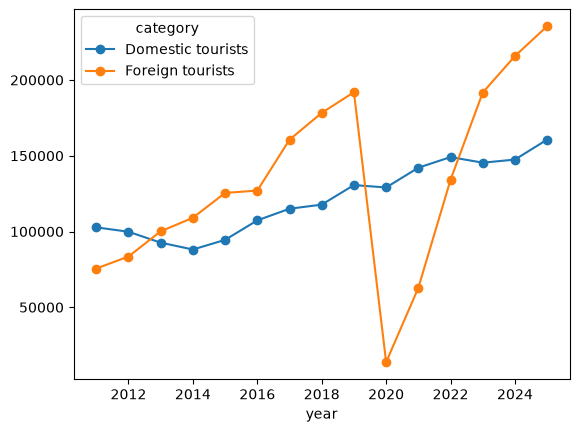

In [245]:
yearly.unstack().drop(2026).plot(marker="o")

In [246]:
jan_aug = dom_for[dom_for["month"] <= 8]
jan_aug.groupby(["year", "category"])["tourists"].sum().unstack()

category,Domestic tourists,Foreign tourists
year,,
2011,88052.0,54517.0
2012,84827.0,59275.0
2013,78959.0,70987.0
2014,72158.0,77966.0
2015,74666.0,91739.0
2016,85503.0,87066.0
2017,91946.0,112741.0
2018,92113.0,130686.0
2019,101598.0,132844.0


In [247]:
table = jan_aug.groupby(["year", "category"])["tourists"].sum().unstack()
change = (table.pct_change() * 100).round(1)
change

category,Domestic tourists,Foreign tourists
year,,
2011,NaN,NaN
2012,-3.7,8.7
2013,-6.9,19.8
2014,-8.6,9.8
2015,3.5,17.7
2016,14.5,-5.1
2017,7.5,29.5
2018,0.2,15.9
2019,10.3,1.7


In [248]:
y2025 = tidy[tidy["year"] == 2025]
countries = y2025[~y2025["category"].isin(["Domestic tourists", "Foreign tourists"])]
by_country = countries.groupby("category")["tourists"].sum().sort_values(ascending=False)
by_country.head(5)

category
Turkey         66028.0
Germany        26335.0
Serbia         22481.0
Netherlands    10830.0
France          9885.0
Name: tourists, dtype: float64

In [249]:
total = by_country.sum()
share = (by_country / total * 100).round(1)
share.astype(str) + "%"

category
Turkey                                         28.0%
Germany                                        11.2%
Serbia                                          9.5%
Netherlands                                     4.6%
France                                          4.2%
Poland                                          4.0%
Great Britain                                   3.5%
Greece                                          3.3%
Bulgaria                                        2.9%
Croatia                                         2.1%
USA                                             2.1%
Slovenia                                        1.8%
Other Asian countries                           1.7%
Albania                                         1.5%
Austria                                         1.5%
Spain                                           1.4%
Australia                                       1.4%
Romania                                         1.3%
Bosnia and Herzegovina               

In [250]:
y2019 = tidy[tidy["year"] == 2019]
countries = y2019[~y2019["category"].isin(["Domestic tourists", "Foreign tourists"])]
by_country = countries.groupby("category")["tourists"].sum().sort_values(ascending=False)
total = by_country.sum()
share = (by_country / total * 100).round(1)
share.astype(str) + "%"


category
Turkey                                         19.3%
Bulgaria                                        8.9%
Poland                                          8.7%
Netherlands                                     8.5%
Serbia                                          5.2%
Germany                                         5.1%
Other Asian countries                           4.6%
Croatia                                         4.5%
Greece                                          3.2%
Slovenia                                        2.2%
Spain                                           2.1%
USA                                             1.7%
Albania                                         1.7%
Romania                                         1.5%
Australia                                       1.4%
Belgium                                         1.3%
Kosovo                                          1.3%
Israel                                          1.2%
Italy                                

In [251]:
two = tidy[tidy["year"].isin([2019, 2025])]
two = two[~two["category"].isin(["Domestic tourists", "Foreign tourists"])] 
comp = two.groupby(["category", "year"])["tourists"].sum().unstack()
comp.columns = ["tourists_2019", "tourists_2025"]

comp["share_2019"] = (comp["tourists_2019"] / comp["tourists_2019"].sum() * 100).round(1)

comp["share_2025"] = (comp["tourists_2025"] / comp["tourists_2025"].sum() * 100).round(1)

comp["change_%"] = ((comp["tourists_2025"] / comp["tourists_2019"] - 1) * 100). round(1)

comp.sort_values("tourists_2025", ascending=False)

,tourists_2019,tourists_2025,share_2019,share_2025,change_%
category,,,,,
Turkey,37026.0,66028.0,19.3,28.0,78.3
Germany,9762.0,26335.0,5.1,11.2,169.8
Serbia,10035.0,22481.0,5.2,9.5,124.0
Netherlands,16310.0,10830.0,8.5,4.6,-33.6
France,1932.0,9885.0,1.0,4.2,411.6
Poland,16669.0,9350.0,8.7,4.0,-43.9
Great Britain,1810.0,8151.0,0.9,3.5,350.3
Greece,6046.0,7861.0,3.2,3.3,30.0
Bulgaria,17172.0,6718.0,8.9,2.9,-60.9


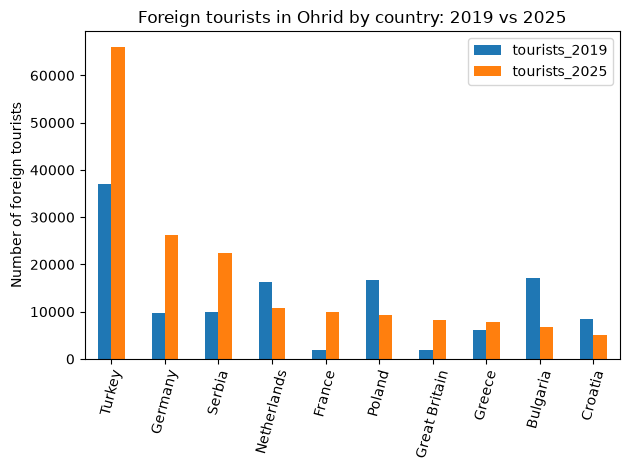

In [252]:
top = comp.sort_values("tourists_2025", ascending=False).head(10)

top[["tourists_2019", "tourists_2025"]].plot(kind="bar")
plt.title("Foreign tourists in Ohrid by country: 2019 vs 2025")
plt.ylabel("Number of foreign tourists")
plt.xlabel("")
plt.xticks(rotation = 75)
plt.tight_layout()
plt.show()


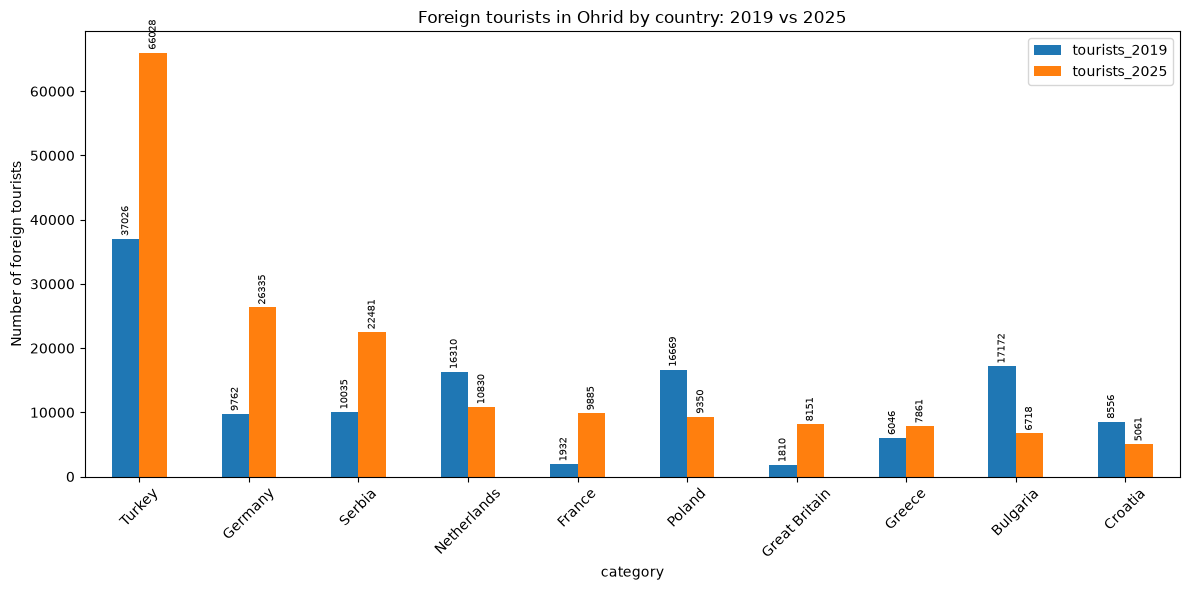

In [253]:
ax = top[["tourists_2019", "tourists_2025"]].plot(kind="bar", figsize=(12, 6))

for bars in ax.containers:
    ax.bar_label(bars, fmt="%d", fontsize=7, rotation=90, padding=2)

plt.title("Foreign tourists in Ohrid by country: 2019 vs 2025")
plt.ylabel("Number of foreign tourists")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [254]:
pbi = tidy[(tidy["year"] > 2015) & (tidy["year"] < 2026)]
pbi.year.unique()

array([2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

In [255]:
pbi = pbi.copy()
pbi["type"] = "Country"
pbi.loc[pbi["category"] == "Domestic tourists", "type"] = "Domestic total"
pbi.loc[pbi["category"] == "Foreign tourists", "type"] = "Foreign total"

pbi["type"].value_counts()
pbi.to_csv("data/ohrid_tourism_2016_2025.csv", index=False)

In [256]:

summer = tidy[(tidy["month"] > 5) & (tidy["month"] < 9)]
summer

measure,municipality,category,period,nights,tourists,year,month
5,Ohrid,Albania,2011M06,600.0,208.0,2011,6
6,Ohrid,Albania,2011M07,1016.0,409.0,2011,7
7,Ohrid,Albania,2011M08,1240.0,434.0,2011,8
17,Ohrid,Albania,2012M06,455.0,235.0,2012,6
18,Ohrid,Albania,2012M07,505.0,244.0,2012,7
...,...,...,...,...,...,...,...
10890,Ohrid,Ukraine,2025M07,411.0,227.0,2025,7
10891,Ohrid,Ukraine,2025M08,241.0,125.0,2025,8
10901,Ohrid,Ukraine,2026M06,363.0,324.0,2026,6
10902,Ohrid,Ukraine,2026M08,612.0,299.0,2026,8


In [257]:
y2020 = tidy[tidy["year"] == 2020]
y2020

measure,municipality,category,period,nights,tourists,year,month
108,Ohrid,Albania,2020M01,452.0,251.0,2020,1
109,Ohrid,Albania,2020M02,131.0,118.0,2020,2
110,Ohrid,Albania,2020M03,9.0,6.0,2020,3
111,Ohrid,Albania,2020M04,0.0,0.0,2020,4
112,Ohrid,Albania,2020M05,0.0,0.0,2020,5
...,...,...,...,...,...,...,...
10831,Ohrid,Ukraine,2020M08,71.0,39.0,2020,8
10832,Ohrid,Ukraine,2020M09,28.0,18.0,2020,9
10833,Ohrid,Ukraine,2020M10,66.0,33.0,2020,10
10834,Ohrid,Ukraine,2020M11,18.0,10.0,2020,11


In [258]:
y2019m7 = tidy[(tidy["year"] == 2019) & (tidy["month"] == 7)]
y2019m7


measure,municipality,category,period,nights,tourists,year,month
102,Ohrid,Albania,2019M07,1282.0,340.0,2019,7
290,Ohrid,Australia,2019M07,2129.0,823.0,2019,7
478,Ohrid,Austria,2019M07,512.0,216.0,2019,7
666,Ohrid,Belarus,2019M07,14.0,5.0,2019,7
854,Ohrid,Belgium,2019M07,3745.0,708.0,2019,7
1042,Ohrid,Bosnia and Herzegovina,2019M07,337.0,147.0,2019,7
1230,Ohrid,Brazil,2019M07,71.0,29.0,2019,7
1418,Ohrid,Bulgaria,2019M07,3260.0,1361.0,2019,7
1606,Ohrid,Canada,2019M07,171.0,76.0,2019,7
1794,Ohrid,China,2019M07,142.0,137.0,2019,7
